In [118]:
import pandas as pd

url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
df = pd.read_csv(url)
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [119]:
print("Shape:", df.shape)
print()
print(df.dtypes)

Shape: (5000, 19)

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object


In [120]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y")

print(df["posted_at"].dtype)
print(df["posted_at"].head())
print("Earliest:", df["posted_at"].min())
print("Latest:", df["posted_at"].max())

datetime64[us]
0   2022-12-17
1   2023-06-02
2   2023-05-07
3   2023-02-12
4   2023-05-23
Name: posted_at, dtype: datetime64[us]
Earliest: 2022-01-01 00:00:00
Latest: 2023-12-31 00:00:00


In [121]:
import numpy as np

impressions = df["impression_count"].to_numpy()
likes = df["likes"].to_numpy()

print("Type:", type(impressions))
print("Shape:", impressions.shape)
print("Impressions - mean:", np.mean(impressions))
print("Impressions - max:", np.max(impressions))
print("Impressions - min:", np.min(impressions))
print("Impressions - total:", np.sum(impressions))
print()
print("Missing likes:", np.isnan(likes).sum())
print("Likes - mean (ignoring missing):", np.nanmean(likes))

Type: <class 'numpy.ndarray'>
Shape: (5000,)
Impressions - mean: 50013.7328
Impressions - max: 99995
Impressions - min: 105
Impressions - total: 250068664

Missing likes: 150
Likes - mean (ignoring missing): 10107.043711340206


In [122]:
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_table = pd.DataFrame({"Missing": missing, "Percent": missing_pct})
missing_table[missing_table["Missing"] > 0]

,Missing,Percent
age,150,3.0
gender,150,3.0
likes,150,3.0
comments,150,3.0
shares,150,3.0
sentiment,150,3.0


In [123]:
df_clean = df.copy()

# Numeric columns -> fill with median
for col in ["age", "likes", "comments", "shares"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Text columns -> fill with mode (most common value)
for col in ["gender", "sentiment"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

# These are whole numbers, so convert back to integers
for col in ["age", "likes", "comments", "shares"]:
    df_clean[col] = df_clean[col].astype(int)

print("Missing values left:", df_clean.isnull().sum().sum())
print(df_clean[["age", "likes", "comments", "shares"]].dtypes)

Missing values left: 0
age         int64
likes       int64
comments    int64
shares      int64
dtype: object


In [124]:
print("Rows before:", len(df_clean))
print("Fully duplicated rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Rows after:", len(df_clean))
print("Repeated post_id values:", df_clean["post_id"].duplicated().sum())

Rows before: 5000
Fully duplicated rows: 0
Rows after: 5000
Repeated post_id values: 9


In [125]:
df_clean["total_interactions"] = df_clean["likes"] + df_clean["comments"] + df_clean["shares"]

print("Likes higher than impressions:", (df_clean["likes"] > df_clean["impression_count"]).sum())
print("Interactions higher than impressions:", (df_clean["total_interactions"] > df_clean["impression_count"]).sum())
print("Engagement rate above 1:", (df_clean["engagement_rate"] > 1).sum())
print()

df_clean[df_clean["likes"] > df_clean["impression_count"]][
    ["likes", "comments", "shares", "impression_count", "engagement_rate"]
].head()

Likes higher than impressions: 464
Interactions higher than impressions: 600
Engagement rate above 1: 603



,likes,comments,shares,impression_count,engagement_rate
4,12682,2735,1300,6019,2.777372
11,19856,1723,905,1816,12.381057
13,15700,1434,1886,389,48.894602
14,13850,586,650,4797,3.144882
19,9252,1542,139,2453,4.456991


In [126]:
# Cap likes, comments, shares so none exceeds impressions
for col in ["likes", "comments", "shares"]:
    df_clean[col] = df_clean[col].clip(upper=df_clean["impression_count"])

# Recalculate interactions and engagement rate, capped at 1 (100%)
df_clean["total_interactions"] = df_clean["likes"] + df_clean["comments"] + df_clean["shares"]
df_clean["engagement_rate"] = (df_clean["total_interactions"] / df_clean["impression_count"]).clip(upper=1)

print("Likes higher than impressions:", (df_clean["likes"] > df_clean["impression_count"]).sum())
print("Engagement rate above 1:", (df_clean["engagement_rate"] > 1).sum())
print("Max engagement rate:", df_clean["engagement_rate"].max())
print("Average engagement rate:", round(df_clean["engagement_rate"].mean(), 3))

Likes higher than impressions: 0
Engagement rate above 1: 0
Max engagement rate: 1.0
Average engagement rate: 0.371


In [127]:
# Count hashtags: each hashtag starts with "#"
df_clean["hashtag_count"] = df_clean["hashtags"].astype(str).str.count("#")

# Clean sentiment labels: remove spaces, lowercase, then capitalise
df_clean["sentiment"] = df_clean["sentiment"].str.strip().str.lower().str.capitalize()

print(df_clean["hashtag_count"].value_counts().sort_index())
print()
print(df_clean["sentiment"].value_counts())

hashtag_count
1    1655
2    1697
3    1648
Name: count, dtype: int64

sentiment
Positive    2513
Neutral     1527
Negative     960
Name: count, dtype: int64


In [128]:
print("Shape:", df_clean.shape)
print()
print("Columns:", list(df_clean.columns))
print()
display(df_clean.head())
display(df_clean.tail())

Shape: (5000, 21)

Columns: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'total_interactions', 'hashtag_count']



,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,total_interactions,hashtag_count
0,25795,43,Female,Brazil,496713,image,fitness,7011,354,1157,...,44650,2022-12-17,81734,False,mobile,Negative,#foodie #travel #love,0.190862,8522,3
1,10860,33,Male,Brazil,157326,reel,food,11750,2606,1807,...,80216,2023-06-02,5963,False,mobile,Negative,#fitness,0.201493,16163,1
2,86820,32,Female,UK,109864,text,food,4862,344,955,...,44858,2023-05-07,501783,False,tablet,Positive,#foodie,0.137345,6161,1
3,64886,51,Other,France,848877,text,fitness,5350,1083,1049,...,70455,2023-02-12,480212,False,mobile,Negative,#music #foodie #fun,0.106195,7482,3
4,16265,34,Other,UK,449706,image,fitness,6019,2735,1300,...,6019,2023-05-23,383936,False,mobile,Negative,#travel,1.000000,10054,1


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,...,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,total_interactions,hashtag_count
4995,59500,44,Male,Australia,441541,video,education,16210,2013,1837,...,42977,2022-06-25,646147,False,mobile,Positive,#travel #fun,0.466761,20060,2
4996,22100,38,Other,UAE,677076,reel,education,16924,2734,1583,...,34196,2022-11-18,584603,False,desktop,Negative,#foodie #reels,0.621155,21241,2
4997,67021,63,Female,USA,273595,text,travel,13487,1497,167,...,23680,2023-04-06,483550,False,desktop,Positive,#lifestyle #tech,0.639823,15151,2
4998,29800,13,Female,Germany,785644,video,fitness,16894,1289,1713,...,89013,2022-05-16,183295,False,tablet,Positive,#reels #love #fitness,0.223518,19896,3
4999,73400,54,Other,Japan,712252,text,travel,14234,503,1798,...,14234,2023-03-04,585760,False,desktop,Neutral,#foodie #lifestyle #fashion,1.000000,16535,3


In [129]:
df_clean.info()
print()
print(df_clean.dtypes)
print()
display(df_clean.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   user_id             5000 non-null   int64         
 1   age                 5000 non-null   int64         
 2   gender              5000 non-null   str           
 3   country             5000 non-null   str           
 4   post_id             5000 non-null   int64         
 5   post_type           5000 non-null   str           
 6   post_category       5000 non-null   str           
 7   likes               5000 non-null   int64         
 8   comments            5000 non-null   int64         
 9   shares              5000 non-null   int64         
 10  watch_time_sec      5000 non-null   int64         
 11  impression_count    5000 non-null   int64         
 12  posted_at           5000 non-null   datetime64[us]
 13  follower_count      5000 non-null   int64         
 14  is_

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,total_interactions,hashtag_count
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000,5000.00,5000.00,5000.00,5000.00
mean,54561.89,38.44,548042.91,9457.72,1489.34,995.59,4014.50,50013.73,2022-12-28 13:21:30.240000,393698.22,0.37,11942.65,2.00
min,10055.00,13.00,100068.00,10.00,0.00,0.00,0.00,105.00,2022-01-01 00:00:00,87.00,0.01,193.00,1.00
25%,32309.50,26.00,322543.50,4561.25,765.00,501.00,2017.75,24988.25,2022-07-03 18:00:00,194480.00,0.15,7139.00,1.00
50%,54374.50,38.00,548077.50,9382.00,1497.00,1012.00,4034.50,49934.50,2022-12-27 00:00:00,388982.00,0.25,11799.50,2.00
75%,77180.50,51.00,771574.50,14155.75,2227.25,1470.00,6020.25,74662.25,2023-06-28 00:00:00,589744.25,0.50,16676.50,3.00
max,99963.00,64.00,999455.00,19998.00,2999.00,1999.00,7998.00,99995.00,2023-12-31 00:00:00,799533.00,1.00,24680.00,3.00
std,26090.37,14.69,260646.96,5667.38,857.36,570.21,2308.10,28844.94,NaN,230927.88,0.30,5780.94,0.81


In [130]:
cat_cols = ["gender", "country", "post_type", "post_category", "device_type", "sentiment"]

for col in cat_cols:
    print("Column:", col)
    print("Unique values:", df_clean[col].unique())
    print("Number of unique values:", df_clean[col].nunique())
    print(df_clean[col].value_counts())
    print("-" * 40)

Column: gender
Unique values: <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
Number of unique values: 3
gender
Male      1849
Other     1581
Female    1570
Name: count, dtype: int64
----------------------------------------
Column: country
Unique values: <StringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str
Number of unique values: 10
country
India        535
Canada       513
Brazil       504
UAE          503
USA          501
France       496
UK           493
Australia    493
Germany      490
Japan        472
Name: count, dtype: int64
----------------------------------------
Column: post_type
Unique values: <StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
Number of unique values: 4
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64
----------------------------------------
Column: post_category
U

In [131]:
numeric_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
                "impression_count", "follower_count", "engagement_rate"]

corr = df_clean[numeric_cols].corr().round(2)
corr

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
age,1.00,-0.03,-0.01,0.01,0.01,0.01,-0.02,-0.02
likes,-0.03,1.00,0.01,0.02,0.00,0.19,-0.03,0.16
comments,-0.01,0.01,1.00,0.02,-0.02,0.02,-0.01,0.04
shares,0.01,0.02,0.02,1.00,0.02,0.02,-0.01,0.02
watch_time_sec,0.01,0.00,-0.02,0.02,1.00,-0.00,0.00,0.01
impression_count,0.01,0.19,0.02,0.02,-0.00,1.00,-0.02,-0.79
follower_count,-0.02,-0.03,-0.01,-0.01,0.00,-0.02,1.00,-0.00
engagement_rate,-0.02,0.16,0.04,0.02,0.01,-0.79,-0.00,1.00


In [132]:
print("Average likes by post type:")
print(df_clean.groupby("post_type")["likes"].mean().round(2).sort_values(ascending=False))
print()
print("Average impressions by country:")
print(df_clean.groupby("country")["impression_count"].mean().round(0).sort_values(ascending=False))

Average likes by post type:
post_type
reel     9513.70
video    9451.88
image    9447.66
text     9415.85
Name: likes, dtype: float64

Average impressions by country:
country
India        52462.0
France       51728.0
USA          51264.0
UK           51119.0
Japan        49616.0
Brazil       49193.0
UAE          48928.0
Canada       48703.0
Germany      48605.0
Australia    48346.0
Name: impression_count, dtype: float64


In [133]:
df_clean["engagement_score"] = (
    df_clean["likes"] * 1 + df_clean["comments"] * 2 + df_clean["shares"] * 3
)

df_clean["log_impressions"] = np.log1p(df_clean["impression_count"])
df_clean["log_followers"] = np.log1p(df_clean["follower_count"])
df_clean["log_likes"] = np.log1p(df_clean["likes"])

df_clean[["engagement_score", "log_impressions", "log_followers", "log_likes"]].describe().round(2)

,engagement_score,log_impressions,log_followers,log_likes
count,5000.00,5000.00,5000.00,5000.00
mean,15423.18,10.52,12.57,8.84
std,6218.83,0.98,1.00,1.00
min,264.00,4.66,4.48,2.40
25%,10603.00,10.13,12.18,8.43
50%,15171.00,10.82,12.87,9.15
75%,20325.25,11.22,13.29,9.56
max,31345.00,11.51,13.59,9.90


In [134]:
def summarize(column):
    return (
        df_clean.groupby(column)
        .agg(
            posts=("post_id", "count"),
            avg_likes=("likes", "mean"),
            avg_score=("engagement_score", "mean"),
            avg_rate=("engagement_rate", "mean"),
        )
        .round(3)
        .sort_values("avg_score", ascending=False)
    )

for col in ["post_type", "country", "sentiment"]:
    print("Summary by", col)
    display(summarize(col))

Summary by post_type


,posts,avg_likes,avg_score,avg_rate
post_type,,,,
image,1247,9447.658,15514.431,0.373
reel,1283,9513.701,15434.844,0.360
text,1245,9415.846,15392.508,0.377
video,1225,9451.885,15349.235,0.376


Summary by country


,posts,avg_likes,avg_score,avg_rate
country,,,,
France,496,9570.502,15617.395,0.367
Germany,490,9632.606,15604.386,0.380
India,535,9506.551,15566.593,0.341
Canada,513,9425.926,15468.444,0.377
USA,501,9563.683,15452.116,0.358
Australia,493,9440.913,15417.481,0.395
Japan,472,9459.536,15351.250,0.385
UAE,503,9288.712,15271.753,0.383
Brazil,504,9302.788,15248.028,0.374


Summary by sentiment


,posts,avg_likes,avg_score,avg_rate
sentiment,,,,
Positive,2513,9590.568,15520.287,0.368
Negative,960,9378.514,15382.547,0.375
Neutral,1527,9288.883,15288.906,0.375


In [135]:
stat_cols = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]

stats = pd.DataFrame({
    "mean": df_clean[stat_cols].mean(),
    "median": df_clean[stat_cols].median(),
    "mode": [df_clean[c].mode()[0] for c in stat_cols],
    "std": df_clean[stat_cols].std(),
    "variance": df_clean[stat_cols].var(),
}).round(3)

stats

,mean,median,mode,std,variance
likes,9457.719,9382.000,10105.0,5667.384,3.211925e+07
comments,1489.343,1497.000,1497.0,857.357,7.350612e+05
shares,995.590,1012.000,1012.0,570.213,3.251432e+05
watch_time_sec,4014.503,4034.500,916.0,2308.096,5.327309e+06
engagement_rate,0.371,0.255,1.0,0.304,9.200000e-02
follower_count,393698.225,388982.000,497502.0,230927.885,5.332769e+10


In [136]:
print("Percentiles:")
display(df_clean[stat_cols].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).round(3).T)

print("Skewness and kurtosis:")
display(pd.DataFrame({
    "skewness": df_clean[stat_cols].skew(),
    "kurtosis": df_clean[stat_cols].kurt(),
}).round(3))

Percentiles:


,0.10,0.25,0.50,0.75,0.90,0.95
likes,1830.900,4561.250,9382.000,14155.750,17565.1,18892.10
comments,298.000,765.000,1497.000,2227.250,2689.0,2858.00
shares,202.000,501.000,1012.000,1470.000,1790.0,1897.00
watch_time_sec,781.400,2017.750,4034.500,6020.250,7212.1,7577.05
engagement_rate,0.086,0.147,0.255,0.504,1.0,1.00
follower_count,76432.300,194480.000,388982.000,589744.250,717755.9,760174.35


Skewness and kurtosis:


,skewness,kurtosis
likes,0.120,-1.124
comments,0.020,-1.149
shares,-0.002,-1.149
watch_time_sec,-0.018,-1.196
engagement_rate,1.065,-0.179
follower_count,0.041,-1.189


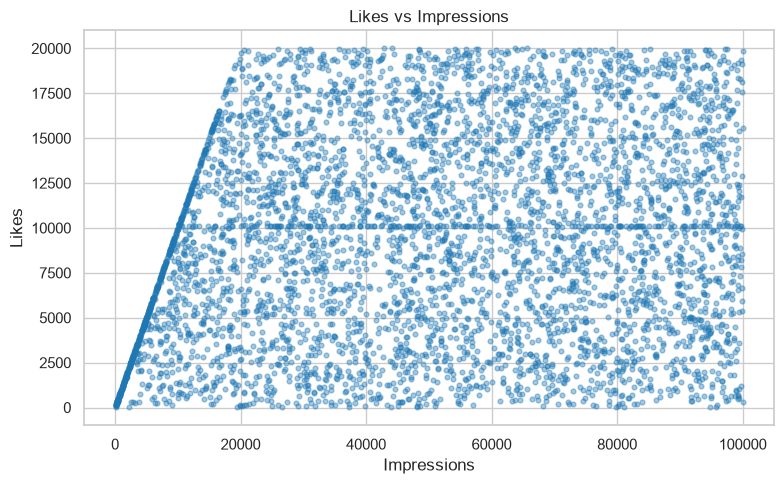

In [137]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
plt.scatter(df_clean["impression_count"], df_clean["likes"], alpha=0.4, s=12, color="tab:blue")
plt.title("Likes vs Impressions")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.tight_layout()
plt.show()

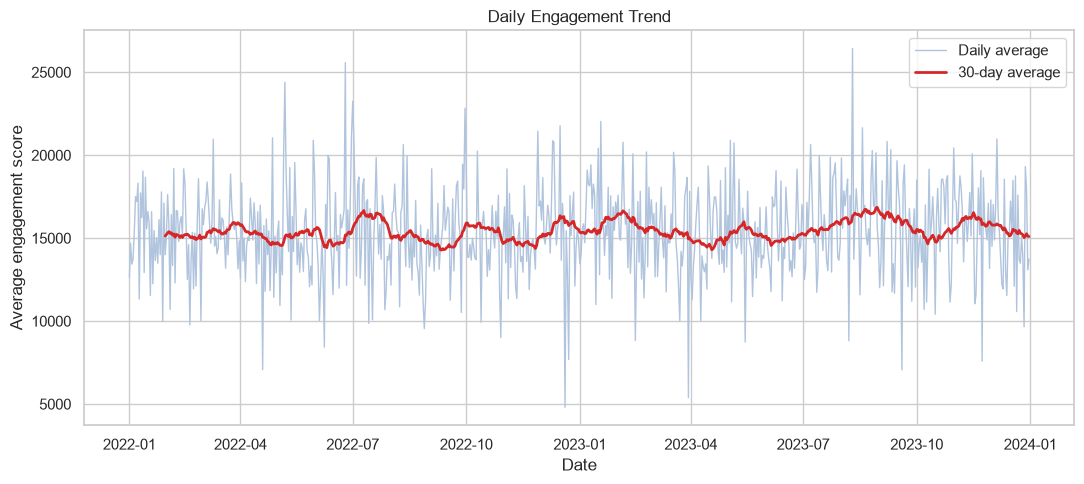

Days plotted: 729


In [138]:
daily = df_clean.groupby("posted_at")["engagement_score"].mean()

plt.figure(figsize=(11, 5))
plt.plot(daily.index, daily.values, color="lightsteelblue", linewidth=1, label="Daily average")
plt.plot(daily.index, daily.rolling(30).mean(), color="tab:red", linewidth=2, label="30-day average")
plt.title("Daily Engagement Trend")
plt.xlabel("Date")
plt.ylabel("Average engagement score")
plt.legend()
plt.tight_layout()
plt.show()

print("Days plotted:", len(daily))

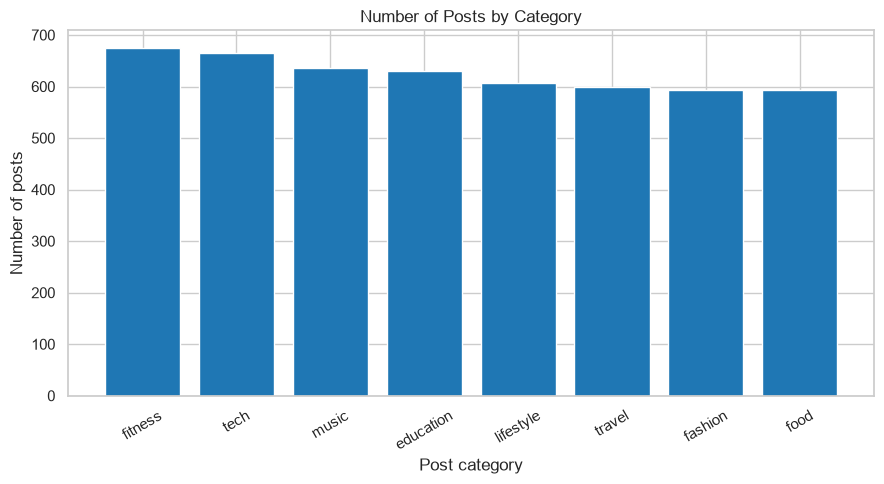

In [139]:
category_counts = df_clean["post_category"].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(category_counts.index, category_counts.values, color="tab:blue")
plt.title("Number of Posts by Category")
plt.xlabel("Post category")
plt.ylabel("Number of posts")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

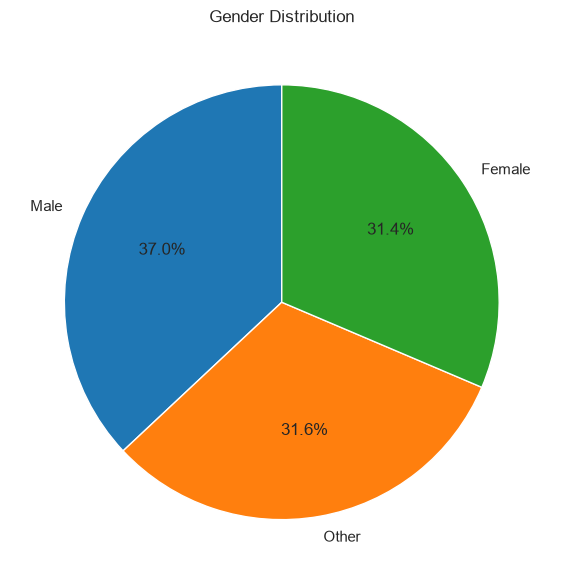

In [140]:
gender_counts = df_clean["gender"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["tab:blue", "tab:orange", "tab:green"],
)
plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

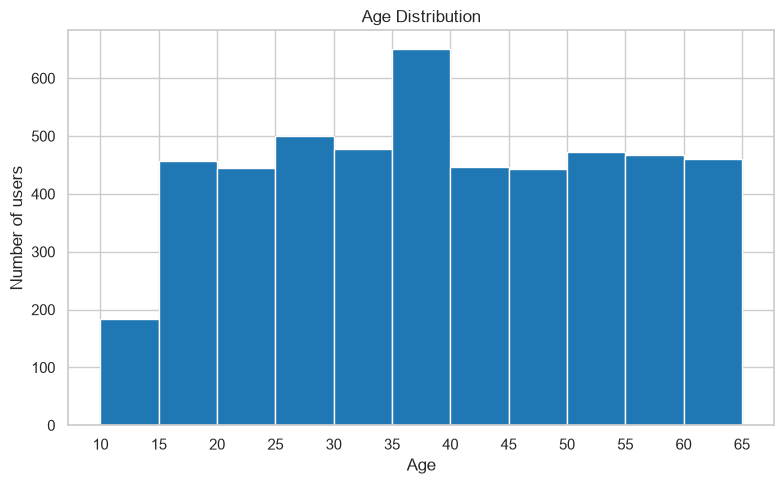

In [141]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["age"], bins=range(10, 70, 5), color="tab:blue", edgecolor="white")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of users")
plt.xticks(range(10, 70, 5))
plt.tight_layout()
plt.show()

C:\Users\bency\AppData\Local\Temp\ipykernel_3352\1168164661.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_clean["engagement_rate"], vert=True, patch_artist=True,


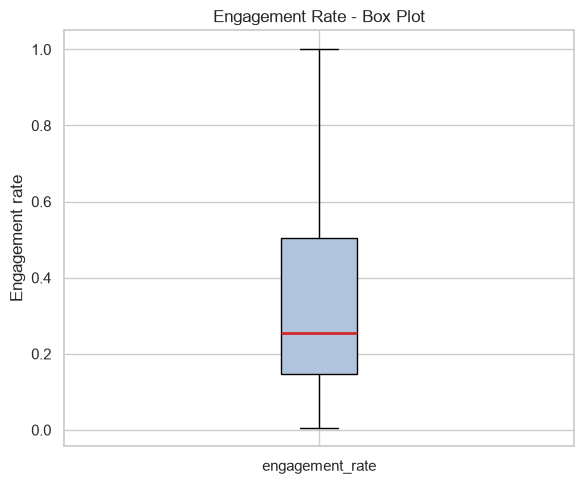

In [142]:
plt.figure(figsize=(6, 5))
plt.boxplot(df_clean["engagement_rate"], vert=True, patch_artist=True,
            boxprops=dict(facecolor="lightsteelblue"),
            medianprops=dict(color="tab:red", linewidth=2))
plt.title("Engagement Rate - Box Plot")
plt.ylabel("Engagement rate")
plt.xticks([1], ["engagement_rate"])
plt.tight_layout()
plt.show()

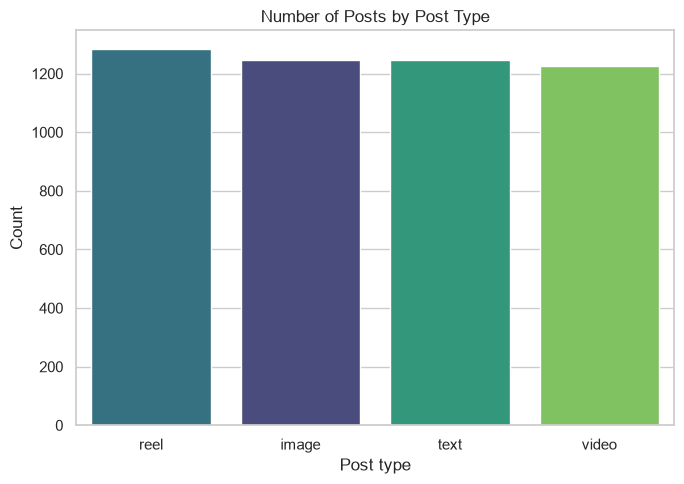

In [143]:
plt.figure(figsize=(7, 5))
order = df_clean["post_type"].value_counts().index
sns.countplot(data=df_clean, x="post_type", order=order, hue="post_type", palette="viridis", legend=False)
plt.title("Number of Posts by Post Type")
plt.xlabel("Post type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

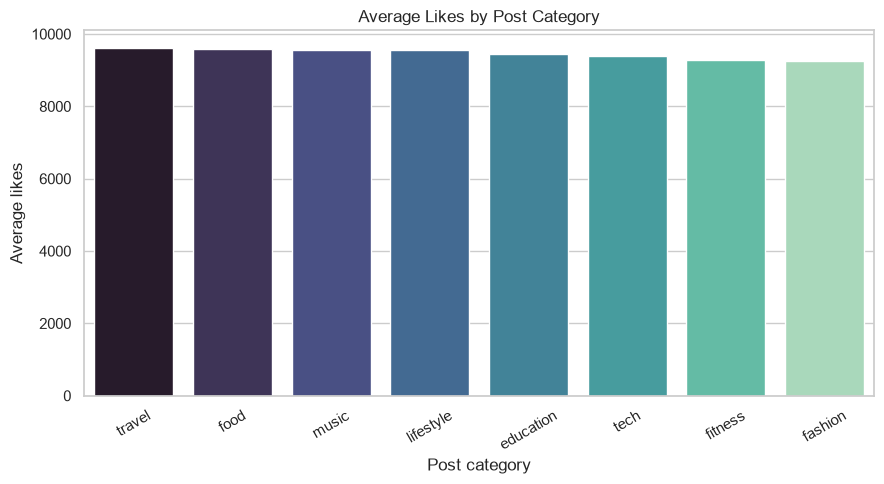

In [144]:
avg_likes = (
    df_clean.groupby("post_category")["likes"].mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=avg_likes, x="post_category", y="likes", hue="post_category", palette="mako", legend=False)
plt.title("Average Likes by Post Category")
plt.xlabel("Post category")
plt.ylabel("Average likes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

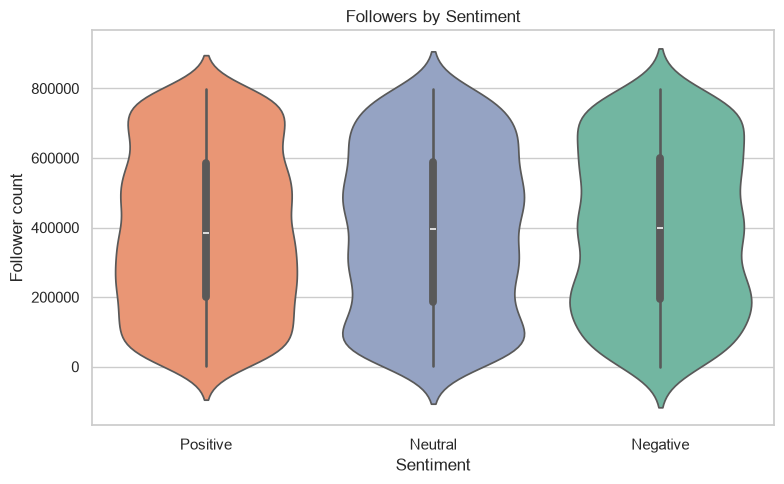

In [145]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df_clean, x="sentiment", y="follower_count",
    order=["Positive", "Neutral", "Negative"],
    hue="sentiment", palette="Set2", legend=False,
)
plt.title("Followers by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Follower count")
plt.tight_layout()
plt.show()

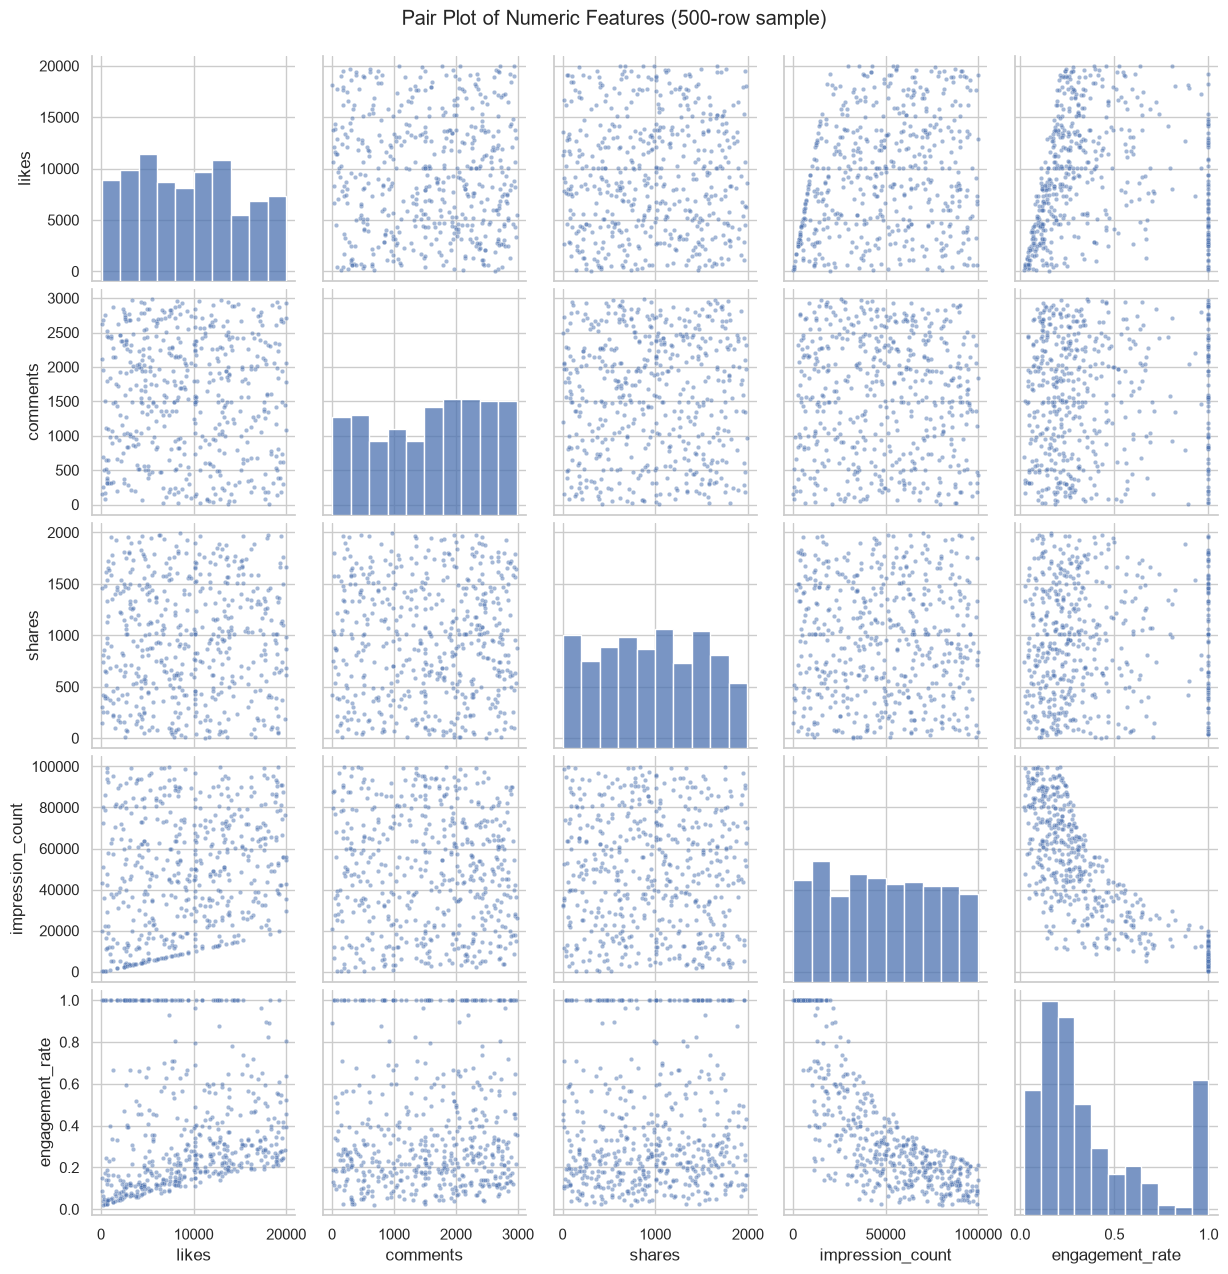

In [146]:
pair_cols = ["likes", "comments", "shares", "impression_count", "engagement_rate"]
sample = df_clean[pair_cols].sample(500, random_state=42)

sns.pairplot(sample, corner=False, plot_kws={"alpha": 0.5, "s": 10})
plt.suptitle("Pair Plot of Numeric Features (500-row sample)", y=1.02)
plt.show()

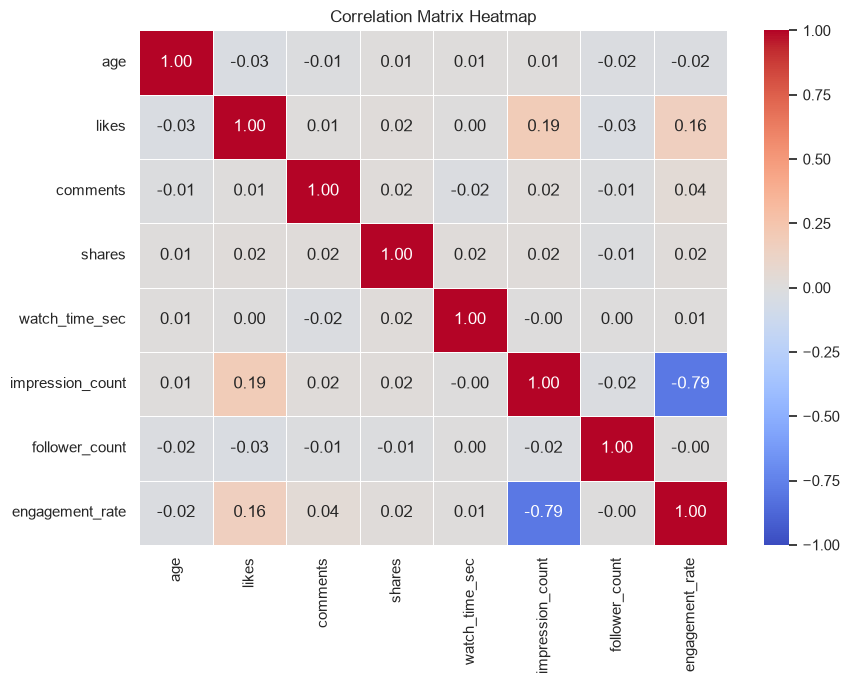

In [147]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

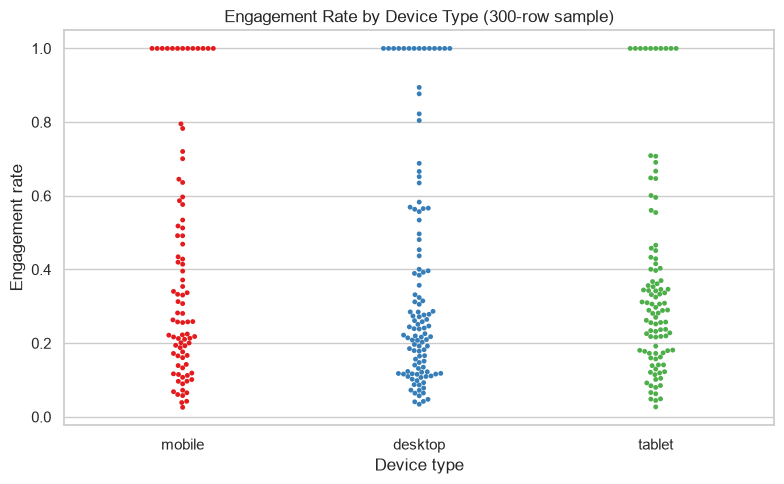

In [148]:
sample = df_clean.sample(300, random_state=42)

plt.figure(figsize=(8, 5))
sns.swarmplot(
    data=sample, x="device_type", y="engagement_rate",
    hue="device_type", palette="Set1", size=3.5, legend=False,
)
plt.title("Engagement Rate by Device Type (300-row sample)")
plt.xlabel("Device type")
plt.ylabel("Engagement rate")
plt.tight_layout()
plt.show()

In [149]:
%pip install plotly nbformat

import plotly.express as px
print("Plotly version:", __import__("plotly").__version__)

Note: you may need to restart the kernel to use updated packages.
Plotly version: 7.1.0



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [150]:
daily_df = (
    df_clean.groupby("posted_at")["engagement_score"].mean().reset_index()
)

fig = px.line(
    daily_df, x="posted_at", y="engagement_score",
    title="Daily Average Engagement Score (Interactive)",
    labels={"posted_at": "Date", "engagement_score": "Average engagement score"},
)
fig.show()

In [151]:
country_rate = (
    df_clean.groupby("country")["engagement_rate"].mean()
    .sort_values(ascending=False)
    .reset_index()
)

fig = px.bar(
    country_rate, x="country", y="engagement_rate",
    color="engagement_rate", color_continuous_scale="Blues",
    title="Average Engagement Rate by Country (Interactive)",
    labels={"country": "Country", "engagement_rate": "Average engagement rate"},
)
fig.show()

In [152]:
bubble = (
    df_clean.groupby("post_category")
    .agg(
        posts=("post_id", "count"),
        avg_impressions=("impression_count", "mean"),
        avg_score=("engagement_score", "mean"),
    )
    .round(0)
    .reset_index()
)

fig = px.scatter(
    bubble, x="avg_impressions", y="avg_score",
    size="posts", color="post_category", text="post_category",
    size_max=45,
    title="Post Categories: Impressions vs Engagement Score (Bubble Size = Number of Posts)",
    labels={"avg_impressions": "Average impressions", "avg_score": "Average engagement score"},
)
fig.update_traces(textposition="top center")
fig.show()

In [153]:
fig = px.scatter(
    df_clean.sample(1500, random_state=42),
    x="follower_count", y="engagement_score",
    color="post_type",
    hover_data=["country", "post_category", "sentiment", "device_type"],
    opacity=0.6,
    title="Followers vs Engagement Score by Post Type (1,500-row sample)",
    labels={"follower_count": "Followers", "engagement_score": "Engagement score"},
)
fig.show()

In [154]:
for col in ["post_type", "post_category", "country"]:
    print("Content performance by", col)
    display(
        df_clean.groupby(col)[["engagement_score", "engagement_rate"]]
        .mean()
        .round(3)
        .sort_values("engagement_score", ascending=False)
    )

Content performance by post_type


,engagement_score,engagement_rate
post_type,,
image,15514.431,0.373
reel,15434.844,0.360
text,15392.508,0.377
video,15349.235,0.376


Content performance by post_category


,engagement_score,engagement_rate
post_category,,
music,15709.978,0.380
food,15550.056,0.359
travel,15468.995,0.366
lifestyle,15399.484,0.370
tech,15367.683,0.369
fitness,15347.209,0.386
education,15324.458,0.377
fashion,15221.168,0.364


Content performance by country


,engagement_score,engagement_rate
country,,
France,15617.395,0.367
Germany,15604.386,0.380
India,15566.593,0.341
Canada,15468.444,0.377
USA,15452.116,0.358
Australia,15417.481,0.395
Japan,15351.250,0.385
UAE,15271.753,0.383
Brazil,15248.028,0.374


In [155]:
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[12, 17, 24, 34, 44, 54, 64],
    labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55-64"],
)

print("Engagement by age group")
display(
    df_clean.groupby("age_group", observed=True)
    .agg(users=("age", "count"), avg_score=("engagement_score", "mean"), avg_rate=("engagement_rate", "mean"))
    .round(3)
)

print("Engagement by verified status")
display(
    df_clean.groupby("is_verified")
    .agg(posts=("age", "count"), avg_score=("engagement_score", "mean"),
         avg_rate=("engagement_rate", "mean"), avg_followers=("follower_count", "mean"))
    .round(3)
)

print("Correlation of age with engagement:")
print(df_clean[["age", "engagement_score", "engagement_rate"]].corr().round(3))

Engagement by age group


,users,avg_score,avg_rate
age_group,,,
13-17,448,15782.161,0.400
18-24,636,15303.544,0.367
25-34,977,15658.346,0.375
35-44,1096,15518.139,0.373
45-54,916,15347.427,0.372
55-64,927,15046.490,0.356


Engagement by verified status


,posts,avg_score,avg_rate,avg_followers
is_verified,,,,
False,4517,15469.371,0.374,395042.838
True,483,14991.168,0.352,381123.451


Correlation of age with engagement:
                    age  engagement_score  engagement_rate
age               1.000            -0.028           -0.025
engagement_score -0.028             1.000            0.162
engagement_rate  -0.025             0.162            1.000


Average impressions by day of week:
weekday
Monday       50013.0
Tuesday      51309.0
Wednesday    49858.0
Thursday     48119.0
Friday       49431.0
Saturday     50945.0
Sunday       50346.0
Name: impression_count, dtype: float64


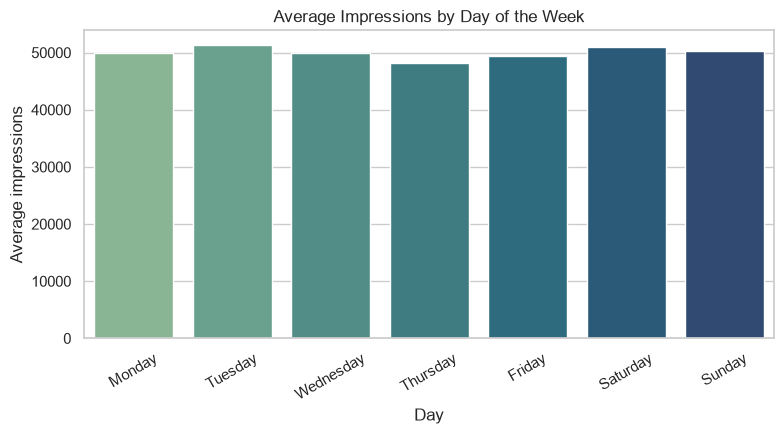

Best month: 9


In [156]:
df_clean["weekday"] = df_clean["posted_at"].dt.day_name()
df_clean["month"] = df_clean["posted_at"].dt.month

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df_clean.groupby("weekday")["impression_count"].mean().reindex(order).round(0)
print("Average impressions by day of week:")
print(by_day)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=by_day.index, y=by_day.values, hue=by_day.index, palette="crest", legend=False)
plt.title("Average Impressions by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average impressions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Best month:", df_clean.groupby("month")["impression_count"].mean().idxmax())

,posts,avg_watch_time,median_watch_time
device_type,,,
mobile,1684,4087.8,4111.0
tablet,1658,3979.7,4072.0
desktop,1658,3974.8,3922.0


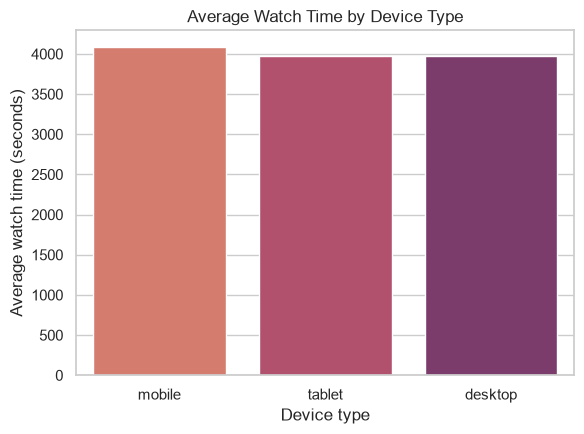

In [157]:
device_watch = (
    df_clean.groupby("device_type")["watch_time_sec"]
    .agg(posts="count", avg_watch_time="mean", median_watch_time="median")
    .round(1)
    .sort_values("avg_watch_time", ascending=False)
)
display(device_watch)

plt.figure(figsize=(6, 4.5))
sns.barplot(data=device_watch.reset_index(), x="device_type", y="avg_watch_time",
            hue="device_type", palette="flare", legend=False)
plt.title("Average Watch Time by Device Type")
plt.xlabel("Device type")
plt.ylabel("Average watch time (seconds)")
plt.tight_layout()
plt.show()

In [158]:
sentiment_summary = (
    df_clean.groupby("sentiment")
    .agg(
        posts=("age", "count"),
        avg_likes=("likes", "mean"),
        avg_comments=("comments", "mean"),
        avg_shares=("shares", "mean"),
        avg_score=("engagement_score", "mean"),
        avg_rate=("engagement_rate", "mean"),
        avg_watch_time=("watch_time_sec", "mean"),
        avg_impressions=("impression_count", "mean"),
    )
    .round(3)
    .sort_values("avg_score", ascending=False)
)
display(sentiment_summary)

print((df_clean["sentiment"].value_counts(normalize=True) * 100).round(1))

,posts,avg_likes,avg_comments,avg_shares,avg_score,avg_rate,avg_watch_time,avg_impressions
sentiment,,,,,,,,
Positive,2513,9590.568,1469.062,997.198,15520.287,0.368,3988.646,50248.107
Negative,960,9378.514,1500.251,1001.177,15382.547,0.375,4054.640,50191.960
Neutral,1527,9288.883,1515.863,989.432,15288.906,0.375,4031.823,49515.971


sentiment
Positive    50.3
Neutral     30.5
Negative    19.2
Name: proportion, dtype: float64


# Social Media Engagement Analytics: Summary of Findings

**Data:** 5,000 posts (Jan 2022 – Dec 2023), 19 original columns. **Cleaning:** 150 missing values in each of 6 columns filled (median for numbers, mode for text); no duplicate rows; 600 rows (12%) had more interactions than impressions, so likes/comments/shares were capped at impressions and engagement rate at 1.0. Added `hashtag_count`, `engagement_score` (likes + 2×comments + 3×shares) and log columns.

## Content Performance
- **Post type:** Image has the highest engagement score (15,514), then reel (15,435), text (15,393) and video (15,349). By engagement rate, text is highest (0.377).
- **Category:** Music performs best (score 15,710). Fitness has the highest rate (0.386). Fashion is lowest (15,221).
- **Country (avg engagement rate):** Australia is highest (0.395), then Japan (0.385) and UAE (0.383). India is lowest (0.341).

## User Trends
- **Age:** Users aged 13–17 engage most (score 15,782, rate 0.400); 55–64 engage least (15,046, rate 0.356). The correlation between age and engagement is very weak (-0.03).
- **Verified accounts:** 483 posts (about 10%). They do slightly worse than non-verified: score 14,991 vs 15,469, rate 0.352 vs 0.374.

## Behavioral Insights
- **Timing:** The data has dates only, with no time of day, so the day of the week was used. Tuesday gets the most impressions (51,309) and Thursday the fewest (48,119). September is the best month.
- **Device:** Mobile has the longest average watch time (4,088 s), vs tablet (3,980 s) and desktop (3,975 s).

## Sentiment
- **Positive** posts perform best (avg likes 9,591, score 15,520) and make up 50.3% of posts.
- **Negative and neutral** posts have a slightly higher engagement rate (0.375 vs 0.368) but fewer likes. Negative posts get more comments (1,500 vs 1,469) and longer watch time (4,055 s vs 3,989 s) than positive posts.

## Statistics and Conclusion
Impressions and engagement rate are strongly negatively correlated (-0.79), because impressions are the divisor in the rate. Engagement rate is right-skewed (skewness 1.07); the other metrics are close to evenly spread. Most correlations are near zero. **Overall, differences between post types, categories, countries, devices and sentiments are small (usually under 3%), so engagement in this dataset depends little on these factors.**